# Fisher Information Analysis and Model Cross-Fitting

Code used to run analysis and generate plots for "Mitigating effects of jitter through differentiable
forwards-modeling for the TOLIMAN space telescope".

In [1]:
import os

import jax
from jax import numpy as np, random as jr, Array
import zodiax as zdx
import dLux as dl
import dLuxToliman as dlT

# Enable 64bit precision (note this must be run in the first cell of the notebook)
jax.config.update("jax_enable_x64", True)

import optax
from tqdm.notebook import tqdm
import random
from datetime import datetime

# plotting
import matplotlib as mpl
from matplotlib import pyplot as plt
import scienceplots
import cmasher as cmr

plt.style.use(["science", "no-latex"])
plt.rcParams["image.origin"] = "lower"
plt.rcParams["figure.dpi"] = 300

# Colour schemes
ito_seven = [
    "#0072B2",
    "#D55E00",
    "#009E73",
    "#CC79A7",
    "#56B4E9",
    "#E69F00",
    "#F0E442",
]
contrast_three = ["#004488", "#BB5566", "#DDAA33"]

files_path = ""
# files_path = "/fred/oz440/max/code/tolicode/files/"

ERROR:2026-10-30 12:03:39,798:jax._src.xla_bridge:477: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/home/mcharles/.conda/envs/jitter/lib/python3.12/site-packages/jax/_src/xla_bridge.py", line 475, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/home/mcharles/.conda/envs/jitter/lib/python3.12/site-packages/jax_plugins/xla_cuda12/__init__.py", line 328, in initialize
    _check_cuda_versions(raise_on_first_error=True)
  File "/home/mcharles/.conda/envs/jitter/lib/python3.12/site-packages/jax_plugins/xla_cuda12/__init__.py", line 285, in _check_cuda_versions
    local_device_count = cuda_versions.cuda_device_count()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: jaxlib/cuda/versions_helpers.cc:113: operation cuInit(0) failed: CUDA_ERROR_NO_DEVICE


## No Jitter

In [2]:
fisher = np.load(files_path + "results/matrices/fisher.npy")
covariance = np.load(files_path + "results/matrices/covariance.npy")

baseline_params = [
    r"sep",
    r"pa",
    r"$x$",
    r"$y$",
    r"$\log{F}$",
    r"cont",
    r"$Z_4$",
    r"$Z_5$",
    r"$Z_6$",
    r"$Z_7$",
    r"$Z_8$",
    r"$Z_9$",
    r"$Z_{10}$",
]

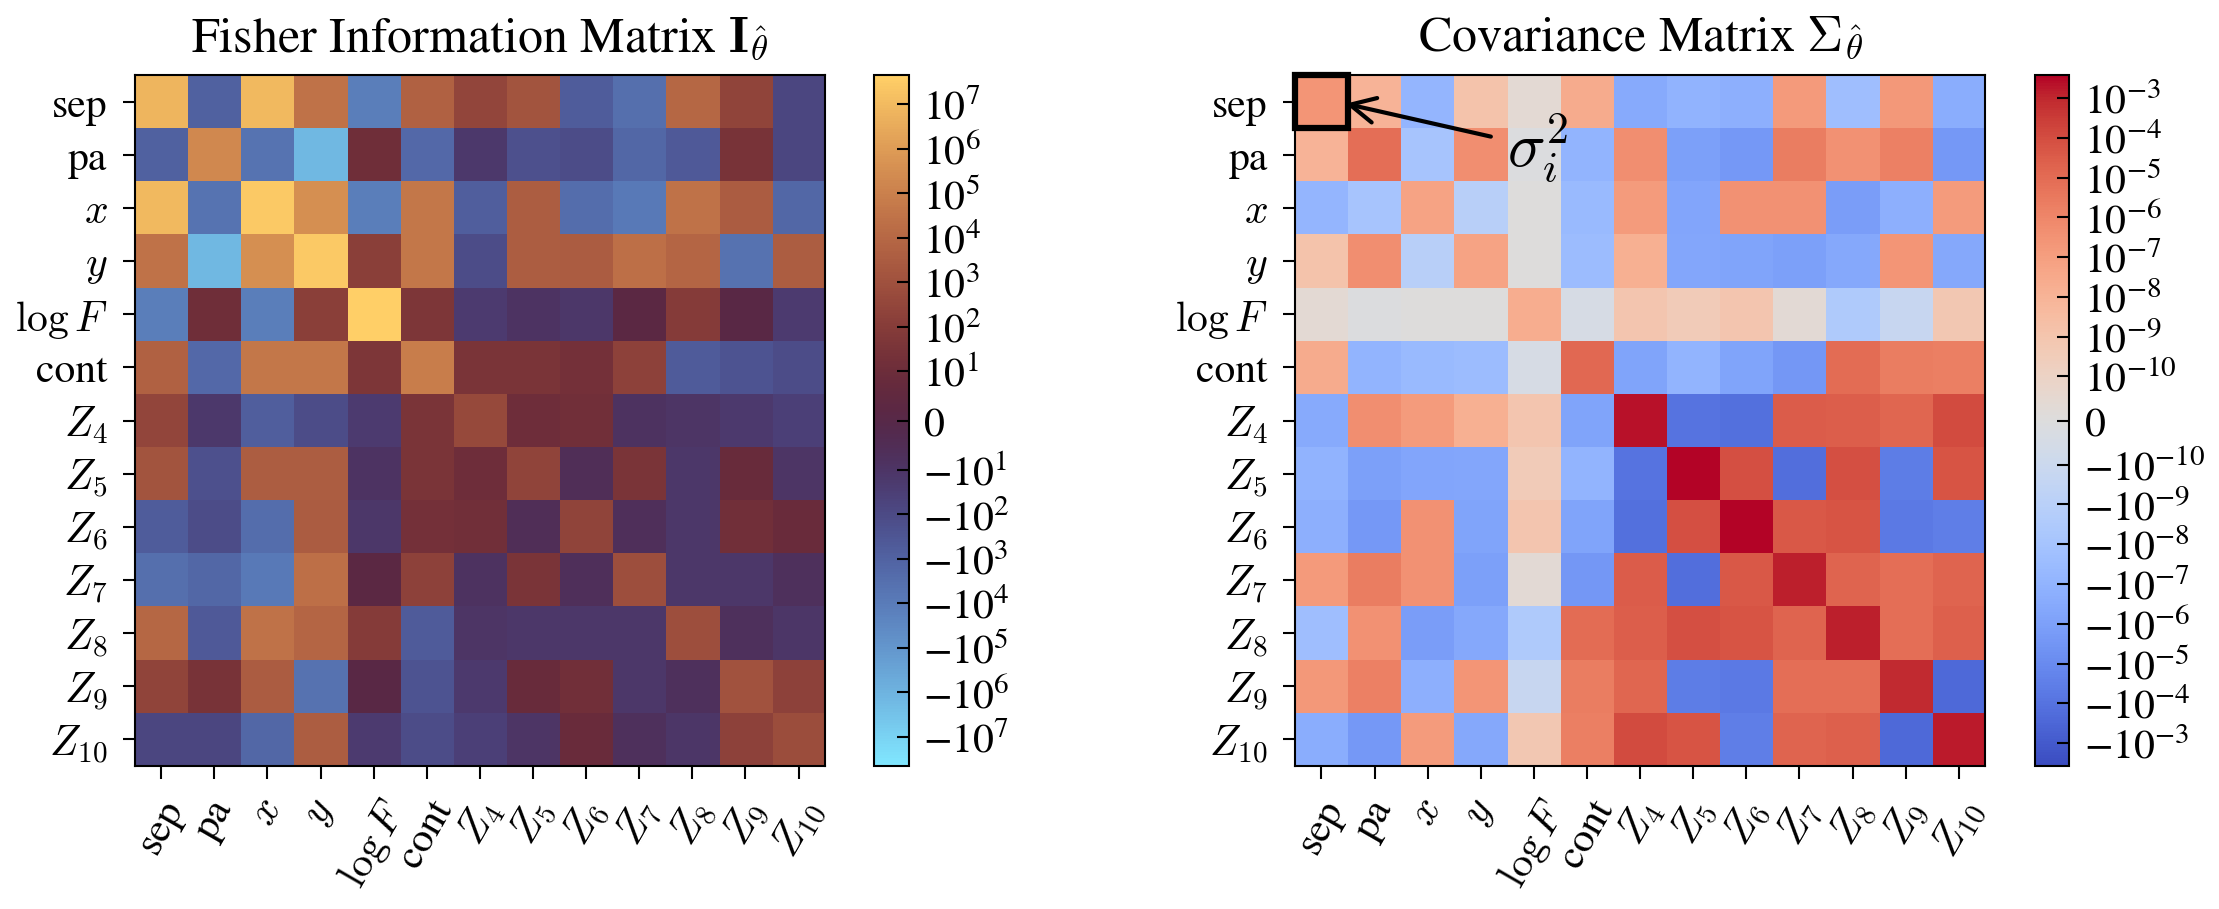

In [3]:
n = len(baseline_params)
ticks = np.arange(n)

fig, ax = plt.subplots(1, 2, figsize=(8, 3.1))
vmax = np.max(np.abs(fisher))
im = ax[0].imshow(
    fisher,
    origin="upper",
    cmap="managua_r",
    norm=mpl.colors.SymLogNorm(linthresh=1e1, vmin=-vmax, vmax=vmax),
)

fig.colorbar(im, ax=ax[0])
ax[0].set(
    title=r"Fisher Information Matrix $\mathbf{I}_{\boldsymbol{\hat{\theta}}}$",
    xticks=ticks,
    yticks=ticks,
    xticklabels=baseline_params,
    yticklabels=baseline_params,
)
ax[0].tick_params(axis="both", direction="out")
ax[0].tick_params(axis="x", rotation=60)
ax[0].tick_params(axis="both", which="both", top=False, right=False)
ax[0].minorticks_off()

vmax = np.max(np.abs(covariance))
im = ax[1].imshow(
    covariance,
    origin="upper",
    cmap="coolwarm",
    norm=mpl.colors.SymLogNorm(linthresh=1e-10, vmin=-vmax, vmax=vmax),
)
rect = mpl.patches.Rectangle(
    (-0.5, -0.5),
    1,
    1,
    facecolor="none",
    edgecolor="k",
    linewidth=1.5,
    clip_on=False,
)
ax[1].annotate(
    r"$\sigma_i^2$",
    xy=(0.3, 0),
    xytext=(3.5, 1.2),
    fontsize=15,
    color="black",
    weight="bold",
    arrowprops=dict(arrowstyle="->", color="black", lw=1),
)
ax[1].add_patch(rect)
fig.colorbar(im, ax=ax[1])
ax[1].set(
    title=r"Covariance Matrix $\mathbf{\Sigma_{\boldsymbol{\hat{\theta}}}}$",
    xticks=ticks,
    yticks=ticks,
    xticklabels=baseline_params,
    yticklabels=baseline_params,
)

ax[1].tick_params(axis="x", rotation=60)
ax[1].tick_params(axis="both", direction="out")
ax[1].tick_params(axis="both", which="both", top=False, right=False)
ax[1].minorticks_off()

plt.tight_layout()
plt.savefig(files_path + "figs/matrices.pdf", dpi=500)
plt.savefig(files_path + "figs/matrices.png", dpi=500)
plt.show()

## Linear & SHM Models: FIA

The results of the Fisher Information analysis for the Linear and SHM jitter models, and their respective plots.
The actual calculation is performed in the `FIA.py` script; here we simply load and plot the saved results.

In [4]:
seps_lin = np.load(files_path + "results/lin/fia_seps.npy")
seps_shm = np.load(files_path + "results/shm/fia_seps.npy")
baseline = np.load(files_path + "results/baseline.npy")
test_mags = np.load(files_path + "results/lin/test_mags.npy")
test_angs = np.load(files_path + "results/lin/test_angs.npy")

sigma_N = 1e-3  # milliarcseconds


def sig_to_N(sigma_i):
    return 0.1 / 60 * (sigma_i / sigma_N) ** 2


def N_to_sig(N):
    return sigma_N * np.sqrt(N * 60 / 0.1)

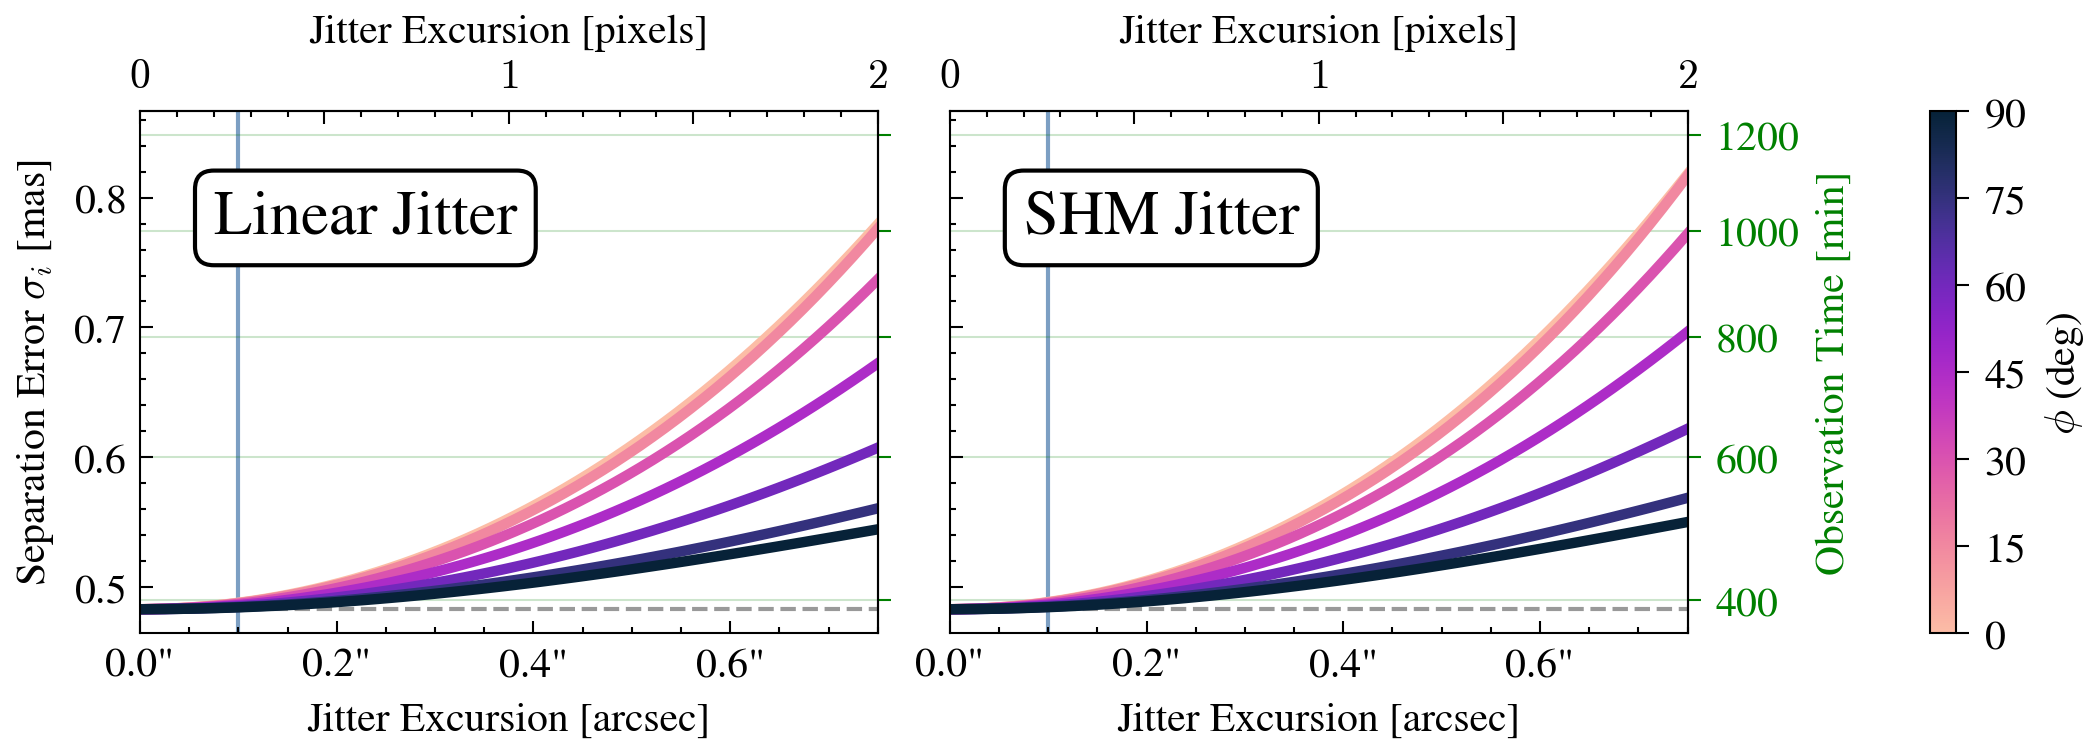

In [5]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

det_pscale = 0.375
colors = ito_seven

cmap = mpl.colormaps["cmr.bubblegum_r"]
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=mpl.colors.Normalize(vmin=0, vmax=90))
colors = cmap(test_angs / 90)

# Create figure with shared y-axis
fig, ax = plt.subplots(1, 2, figsize=(7, 2.5), sharey=True, layout="compressed")

# Store secondary y-axis from first subplot to sync later
ax3_ref = None

for i, seps in enumerate([seps_lin, seps_shm]):
    # Primary baseline line
    if baseline is not None:
        ax[i].axhline(
            baseline, linestyle="--", c="k", alpha=0.4, label="No Jitter", linewidth=1
        )
    ax[i].axvline(
        0.1,
        color="#4477AA",
        zorder=-1,
        label="1 pix FWHM",
        alpha=0.7,
    )

    # Plot each line
    for sep, ang, c in zip(seps.T, test_angs, colors):
        ax[i].plot(
            test_mags,
            1000 * sep,
            label=r"$\phi\,=\,$" + f"{ang:.0f}",
            color=c,
            linewidth=2.5,
        )

    # Ticks
    ax[i].tick_params(axis="x", which="both", top=False)
    ax[i].tick_params(axis="y", which="both", right=False)
    ax[i].set(
        xticks=[0, 0.2, 0.4, 0.6],
        xticklabels=['0.0"', '0.2"', '0.4"', '0.6"'],
        xlim=(0, 0.5),
    )

    # Secondary x-axis (top)
    ax2 = ax[i].secondary_xaxis(
        "top", functions=(lambda x: x / det_pscale, lambda x: x * det_pscale)
    )
    ax2.set_xticks([0.0, 1.0, 2.0])
    ax2.set_xticklabels([r"$0$", r"$1$", r"$2$"])
    ax2.minorticks_on()
    ax2.xaxis.set_minor_locator(mpl.ticker.AutoMinorLocator(5))

    ax2.set_xlabel("Jitter Excursion [pixels]")
    ax2.set_xticks([0, 0.5, 1.0, 1.5, 2.0])

    # Secondary y-axis (right)
    t_color = "green"
    ax3 = ax[i].secondary_yaxis("right", functions=(sig_to_N, N_to_sig))
    ax3.tick_params(axis="y", direction="out", colors=t_color)
    ax3.minorticks_off()
    yticks = [400, 600, 800, 1000, 1200]
    ax3.set(yticks=yticks)
    for t in yticks:
        ax[i].axhline(
            N_to_sig(t),
            zorder=-1,
            linestyle="-",
            linewidth=0.5,
            color=t_color,
            alpha=0.2,
        )
    if i == 0:
        ax3.set_yticklabels([])
    else:
        ax3.set_ylabel("Observation Time [min]", color=t_color)

    # # Grid only on primary y
    # ax[i].grid(True, alpha=0.2, linestyle="-", axis="y")

    # Add subplot title text
    title = ["Linear Jitter", "SHM Jitter"][i]
    ax[i].text(
        0.1,
        0.85,
        title,
        size=15,
        transform=ax[i].transAxes,
        ha="left",
        va="top",
        bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.3"),
    )

# Set primary x/y labels
ax[0].set(
    xlabel="Jitter Excursion [arcsec]",
    ylabel=r"Separation Error $\sigma_i$ [mas]",
    xlim=(0, test_mags.max()),
)
ax[1].set(xlabel="Jitter Excursion [arcsec]", xlim=(0, test_mags.max()))

# Colorbar
cbar = fig.colorbar(sm, ax=ax, ticks=test_angs, label=r"$\phi$ (deg)")
cbar.ax.tick_params(direction="out")
cbar.ax.minorticks_off()

# Save and show
plt.savefig(files_path + "figs/lin_shm_sweep.pdf", bbox_inches="tight", dpi=500)
plt.savefig(files_path + "figs/lin_shm_sweep.png", bbox_inches="tight", dpi=500)
plt.show()

## Multivariate Normal Model: FIA

The Fisher Information analysis for the multivariate normal jitter model, and its respective plot. The actual calculation is performed in the `FIA_mvn.py` script; here we simply load and plot the saved results.

In [6]:
# det is GaussianJitter's r: the determinant of the jitter covariance, in arcsec^4
def fwhm_to_det(fwhm, shear):
    return (1 - shear) ** 2 * (fwhm / 2.35482) ** 4


def det_to_fwhm(det, shear):
    return 2.35482 * (det / (1 - shear) ** 2) ** 0.25

In [7]:
test_rs = np.load(files_path + "results/lin/test_rs.npy")
test_shears = np.load(files_path + "results/shm/test_shears.npy")
test_phis = np.load(files_path + "results/lin/test_phis.npy")

seps_mvn = np.load(files_path + "results/mvn/fia_seps.npy")
kernels = np.load(files_path + "results/mvn/kernels.npy")
fwhms = np.load(files_path + "results/mvn/fwhms.npy")

baseline = np.load(files_path + "results/baseline.npy")

kernel_size = 17
oversample = 4

findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.
findfont: Font family 'Georgia' not found.


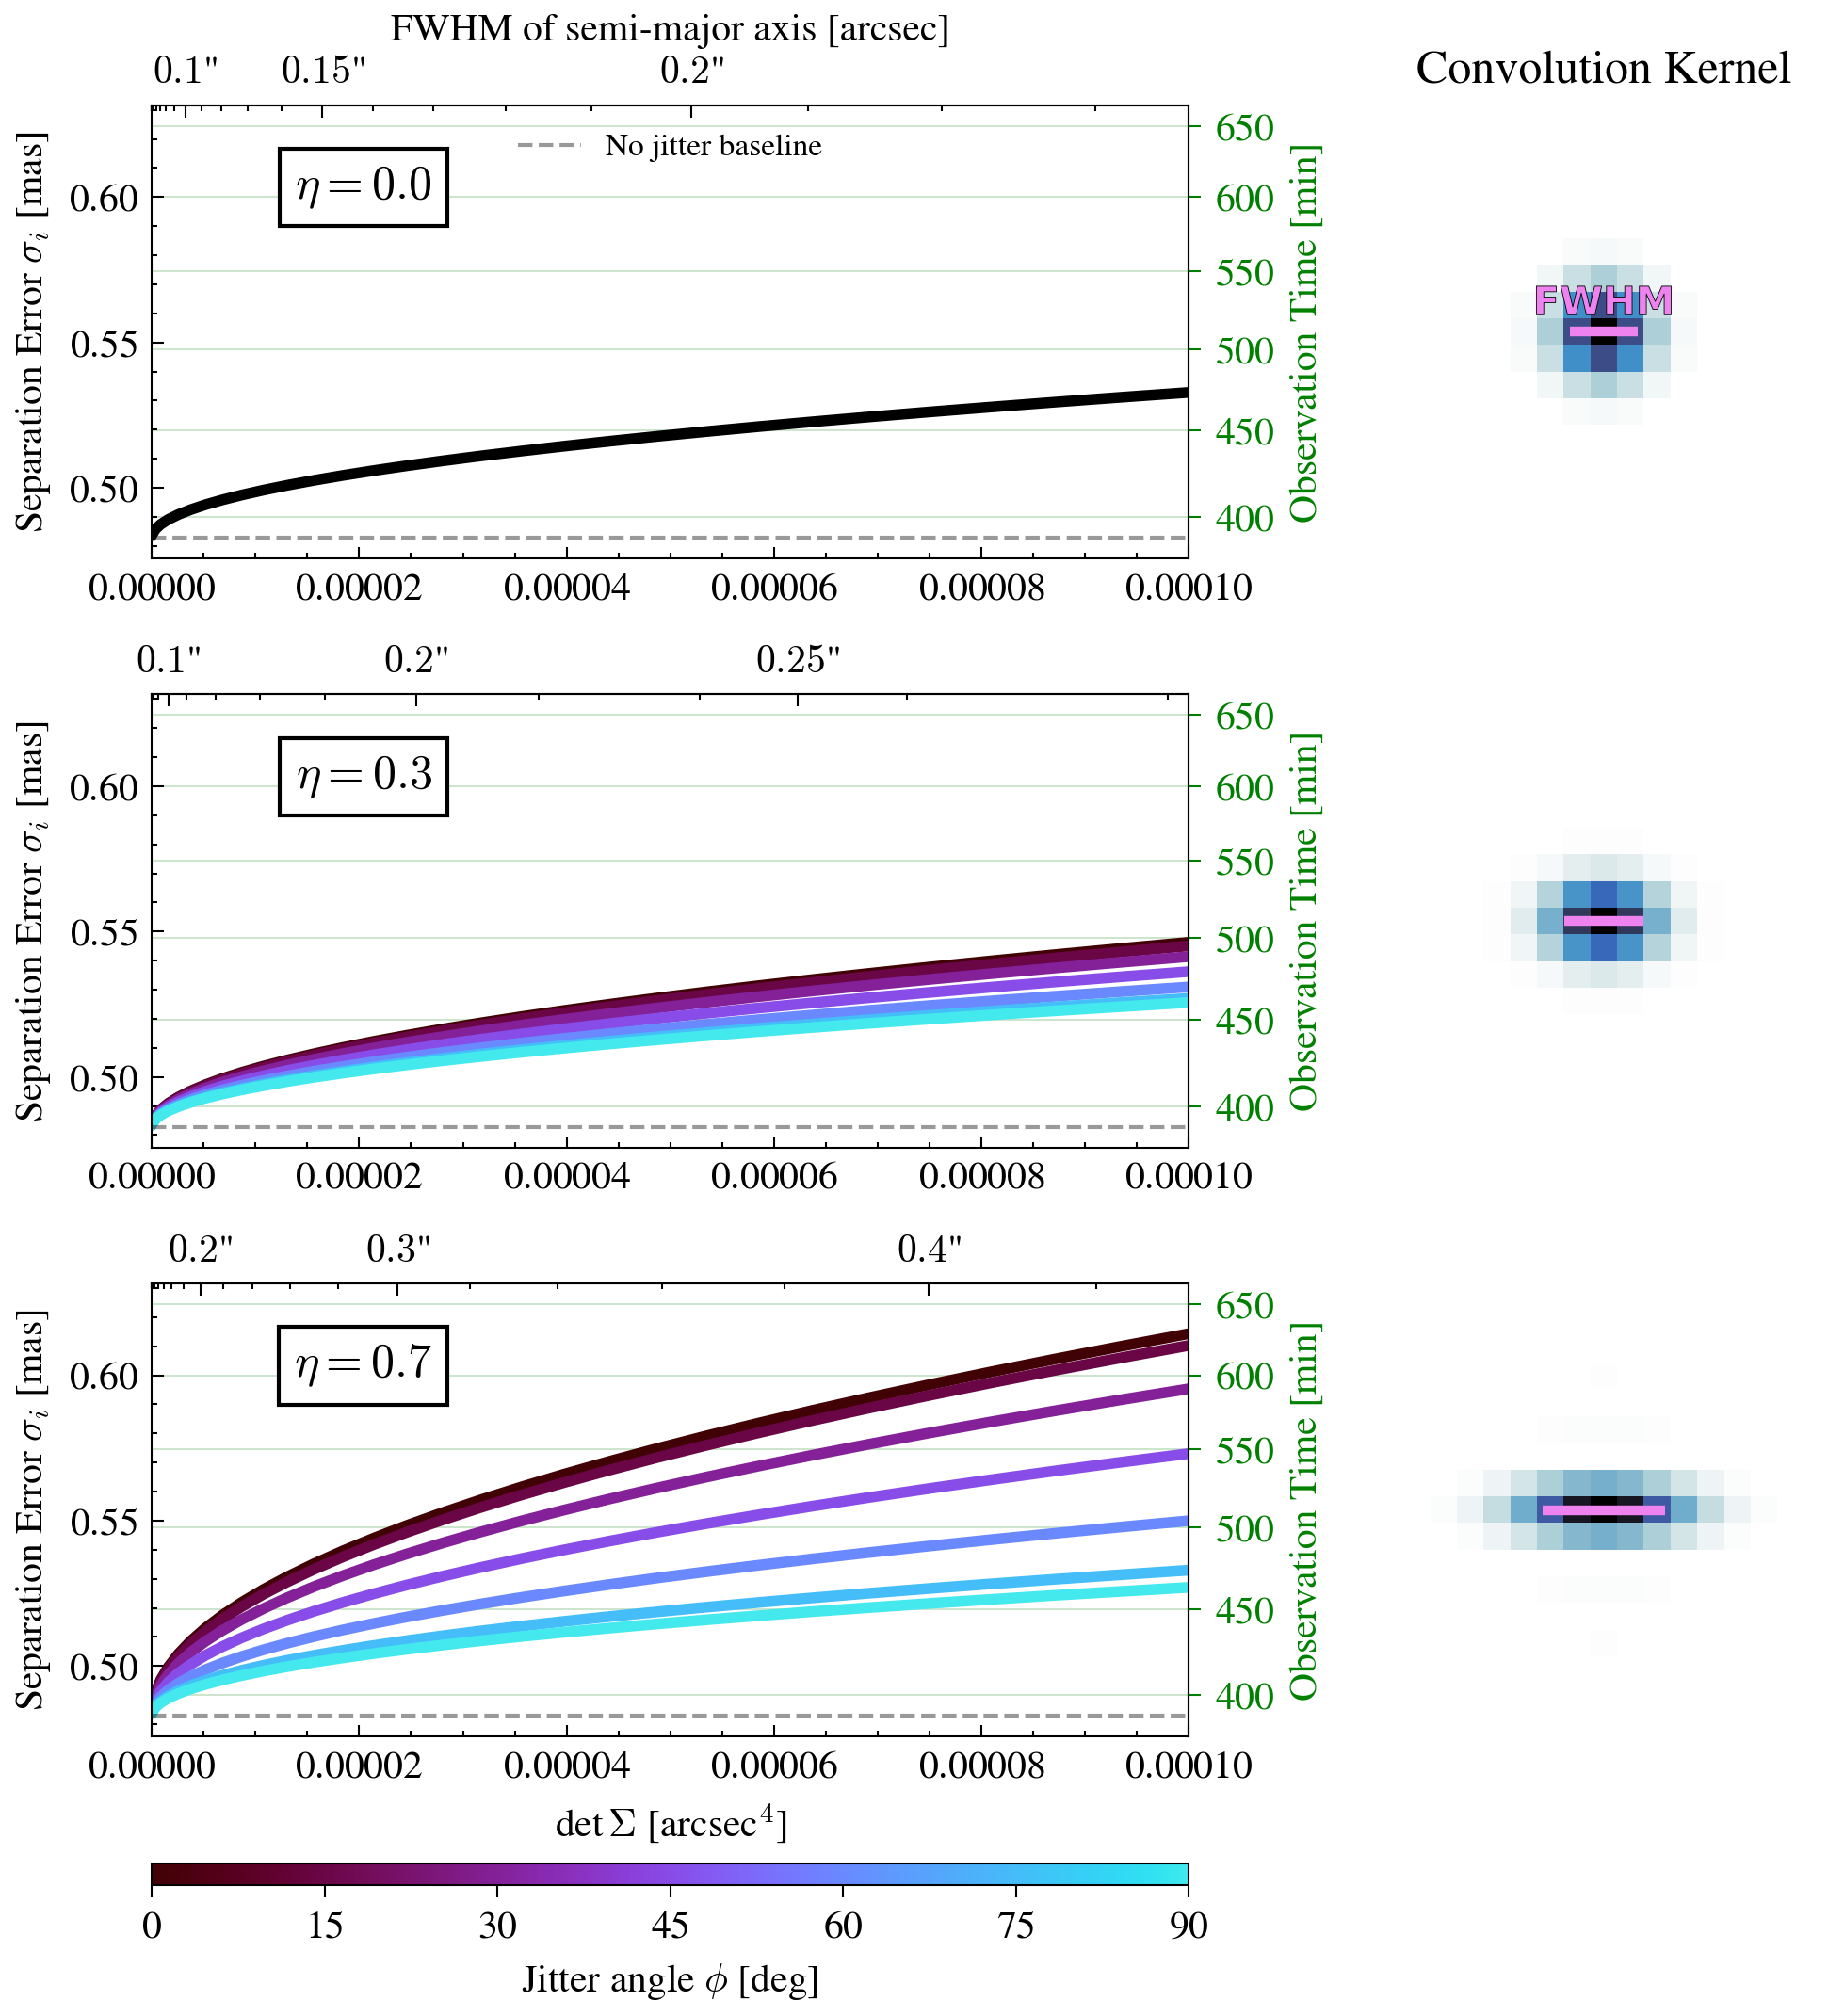

In [15]:
import matplotlib.patheffects as pe

cmap = mpl.colormaps["cmr.gem"]
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=mpl.colors.Normalize(vmin=0, vmax=90))
colors = cmap(test_phis / 90)

fig, axes = plt.subplots(
    len(test_shears),
    2,
    figsize=(9, 7.5),
    gridspec_kw={"hspace": 0.3, "wspace": -0.1},  # sharey="col", layout="compressed",
)

for i, shear in enumerate(test_shears):
    ax, axe = axes[i]
    # ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 2))
    ax.tick_params(axis="x", which="both", top=False)
    ax.tick_params(axis="y", which="both", right=False)

    for sep, phi, c in zip(seps_mvn[i].T, test_phis, colors):
        if shear == 0:
            label = None
            c = "k"
        else:
            label = label = r"$\phi\,=$" + f" {phi:.0f}"
        ax.plot(test_rs, 1000 * sep, label=label, color=c, marker=None, linewidth=2.75)
    ax.set(
        # xlabel=r"det$\,\Sigma$ [arcsec$^{4}$]",
        ylabel=r"Separation Error $\sigma_i$ [mas]",
        # ylim=(baseline - 0.01, 0.8),
        xlim=(0, test_rs.max()),
    )
    if i == 2:
        ax.set(xlabel=r"det$\,\Sigma$ [arcsec$^{4}$]")

    ax.text(
        0.27,
        0.87,
        rf"$\eta={shear}$",
        size=12,
        transform=ax.transAxes,
        ha="right",
        va="top",
        bbox=dict(facecolor="white", edgecolor="black", boxstyle=None),
    )
    ax.axhline(
        baseline,
        linestyle="--",
        c="k",
        alpha=0.4,
        label="No jitter baseline",
        linewidth=1,
    )
    # ax.axvline(
    #     fwhm_to_det(0.1, shear),
    #     color="#4477AA",
    #     zorder=-1,
    #     label='0.1" FWHM',
    #     alpha=0.7,
    # )
    if i == 0:
        ax.legend(
            loc="upper center",
            fontsize=8,
            framealpha=1.0,
            edgecolor="black",
            labelspacing=0.3,
        )

    extent = (
        np.array([-kernel_size / 2, kernel_size / 2, -kernel_size / 2, kernel_size / 2])
        * det_pscale
        / oversample
    )
    c = axe.imshow(
        kernels[i],
        cmap="cmr.arctic_r",
        origin="lower",
        extent=extent,
        vmin=0,
    )
    axe.set(
        xticks=[],
        yticks=[],
    )
    axe.minorticks_off()

    max_fwhm = det_to_fwhm(test_rs.max(), shear)
    axe.hlines(
        0,
        -max_fwhm / 2,
        max_fwhm / 2,
        colors="violet",
        linestyles="solid",
        label="FWHM",
        linewidth=2.5,
    )

    for spine in ["top", "right", "left", "bottom"]:
        axe.spines[spine].set_visible(False)

    if shear == 0:
        axe.set_title("Convolution Kernel")
        axe.text(
            0.0,
            0.1,
            "FWHM",
            size=10,
            ha="center",
            va="center",
            color="violet",
            weight="bold",
            fontname="Georgia",
            # transform=axe.transAxes,
            path_effects=[pe.Stroke(linewidth=0.2, foreground="black")],
        )


# SECONDARY AXES (was buggy so had to remove from loop)

# First subplot
ax00 = axes[0][0].secondary_xaxis(
    "top",
    functions=(
        lambda r: det_to_fwhm(r, test_shears[0]),
        lambda fwhm: fwhm_to_det(fwhm, test_shears[0]),
    ),
)
ax00.set_xticks([0.1, 0.15, 0.2])  # Custom major xticks
ax00.set_xticklabels(
    [r'$0.1$"', r'$0.15$"', r'$0.2$"']
)  # Custom labels for major ticks
ax00.minorticks_on()  # Enable minor ticks
ax00.xaxis.set_minor_locator(
    mpl.ticker.AutoMinorLocator(5)
)  # 5 minor ticks between major ticks
ax00.set_xlabel("FWHM of semi-major axis [arcsec]")

# Second subplot
ax11 = axes[1][0].secondary_xaxis(
    "top",
    functions=(
        lambda r: det_to_fwhm(r, test_shears[1]),
        lambda fwhm: fwhm_to_det(fwhm, test_shears[1]),
    ),
)
ax11.set_xticks([0.1, 0.2, 0.25])  # Custom major xticks
ax11.set_xticklabels(
    [r'$0.1$"', r'$0.2$"', r'$0.25$"']
)  # Custom labels for major ticks
ax11.minorticks_on()  # Enable minor ticks
ax11.xaxis.set_minor_locator(
    mpl.ticker.AutoMinorLocator(5)
)  # 5 minor ticks between major ticks
# ax11.set_xlabel("FWHM of semi-major axis [arcsec]")

# First subplot
ax22 = axes[2][0].secondary_xaxis(
    "top",
    functions=(
        lambda r: det_to_fwhm(r, test_shears[2]),
        lambda fwhm: fwhm_to_det(fwhm, test_shears[2]),
    ),
)
ax22.set_xticks([0.2, 0.3, 0.4])  # Custom major xticks
ax22.set_xticklabels([r'$0.2$"', r'$0.3$"', r'$0.4$"'])  # Custom labels for major ticks
ax22.minorticks_on()  # Enable minor ticks
ax22.xaxis.set_minor_locator(
    mpl.ticker.AutoMinorLocator(5)
)  # 5 minor ticks between major ticks
# ax22.set_xlabel("FWHM of semi-major axis [arcsec]")

# Secondary y-axis (right)
for i in range(len(test_shears)):
    t_color = "green"
    ax3 = axes[i][0].secondary_yaxis("right", functions=(sig_to_N, N_to_sig))
    ax3.tick_params(axis="y", direction="out", colors=t_color)
    ax3.minorticks_off()
    yticks = np.arange(400, 700, 50)
    ax3.set(yticks=yticks)
    ax3.set_ylabel("Observation Time [min]", color=t_color)
    for t in yticks:
        axes[i][0].axhline(
            N_to_sig(t),
            zorder=-1,
            linestyle="-",
            linewidth=0.5,
            color=t_color,
            alpha=0.2,
        )

# --- COLORBAR: left of left column, layout-independent ---

# --- HORIZONTAL COLORBAR BELOW LEFT COLUMN ---

# get left-column span
pos_left_top = axes[0, 0].get_position()
pos_left_bot = axes[-1, 0].get_position()

cax = fig.add_axes(
    [
        pos_left_top.x0,  # align with left column
        pos_left_bot.y0 - 0.07,  # below bottom subplot
        pos_left_top.width,  # same width as left column
        0.01,  # height of colorbar
    ]
)

cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal",
    ticks=test_phis,
)

cbar.set_label(r"Jitter angle $\phi$ [deg]")
cbar.ax.minorticks_off()
cbar.ax.tick_params(direction="out")


plt.savefig(files_path + "figs/mvn_sweep.pdf", bbox_inches="tight", dpi=500)
plt.savefig(files_path + "figs/mvn_sweep.png", bbox_inches="tight", dpi=500)
plt.show()

## Model Cross-Fitting

The code for model cross-fitting to investigate systematic model-introduced bias and a potential increase in separation error.

In [9]:
import numpy as onp


def bootstrap_histogram(histogram: Array, num_bootstraps: int) -> Array:
    """
    Perform bootstrapping on a histogram to get theuncertainty in the mean and standard deviation.
    """
    boot_means = []
    boot_stds = []

    for _ in range(num_bootstraps):
        resampled_data = onp.random.choice(
            histogram,
            size=len(histogram),
            replace=True,
        )
        boot_means.append(np.mean(resampled_data))
        boot_stds.append(np.std(resampled_data, ddof=1))

    # Compute statistics
    mean_estimate = np.mean(histogram)
    std_estimate = np.std(histogram)
    mean_uncertainty = np.std(np.array(boot_means))
    std_uncertainty = np.std(np.array(boot_stds))

    return mean_estimate, mean_uncertainty, std_estimate, std_uncertainty

In [10]:
sep_dict_save_dir = files_path + "results/xfit/"
total_sep_dict = {}

# looping over saved sep_dicts
for f in os.listdir(sep_dict_save_dir):
    if not f.endswith(".npy"):
        continue

    # loading each file
    this_dict = np.load(os.path.join(sep_dict_save_dir, f), allow_pickle=True).item()

    # appending to total_sep_dict
    for k in this_dict.keys():
        total_sep_dict[k] = (
            np.append(total_sep_dict[k], this_dict[k])
            if k in total_sep_dict.keys()
            else this_dict[k]
        )

10080 noise realisations.


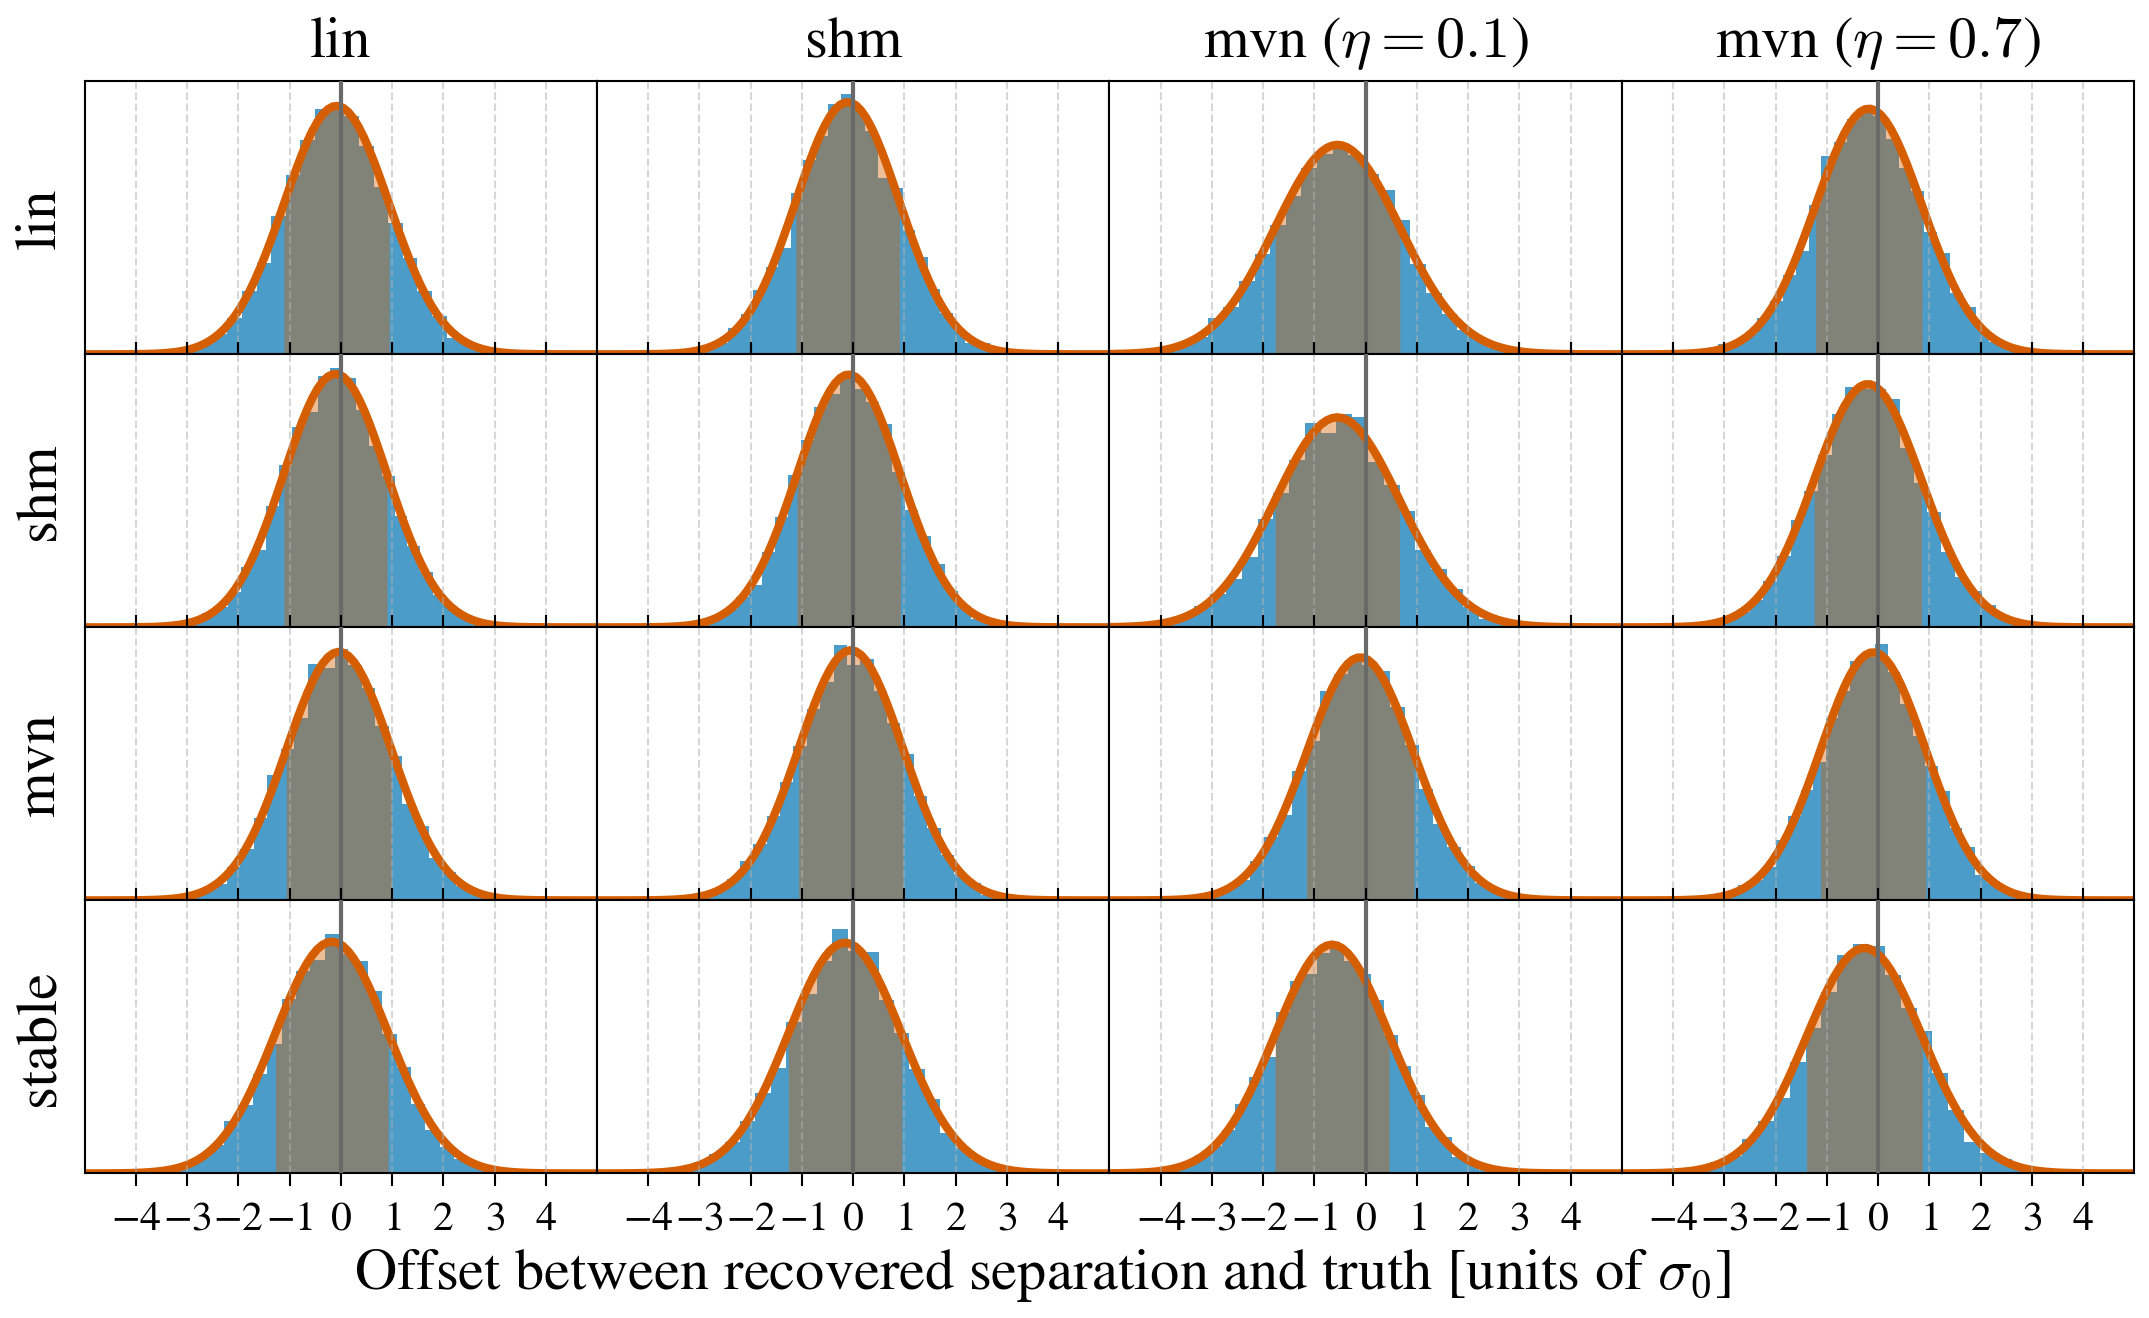

In [11]:
print(f"{len(list(total_sep_dict.values())[0])} noise realisations.")

n_bins = 30
# true_sep = model.separation  # arcseconds
true_sep = 10  # arcseconds
fontsize = 14
sigma_0 = 1e-3 * baseline
model_titles = {"raw": "stable", "lin": "lin", "shm": "shm", "mvn": "mvn"}
data_titles = {
    "lin": "lin",
    "shm": "shm",
    "mvn0": r"mvn ($\eta=0.1$)",
    "mvn07": r"mvn ($\eta=0.7$)",
}
models = ["lin", "shm", "mvn", "raw"]
datas = ["lin", "shm", "mvn0", "mvn07"]


fig, ax = plt.subplots(
    4,
    4,
    figsize=(7.5, 4.5),
    sharex=True,
    sharey=True,
)
fig.subplots_adjust(
    top=0.915,
    bottom=0.106,
    left=0.074,
    right=0.985,
    hspace=0.0,
    wspace=0.0,
)

for i in range(4):
    for j in range(4):

        key = f"{models[i]}_{datas[j]}"
        results = total_sep_dict[key]
        offset_hist = results - true_sep  # in arseconds
        offset_hist /= sigma_0  # converting to sigma units

        # ax[i][j].text(
        #     0.5,
        #     0.5,
        #     f"{i},{j},{key}",
        #     transform=ax[i][j].transAxes,
        #     ha="center",
        #     va="center",
        #     fontsize=12,
        #     bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
        # )

        ax[i][j].hist(
            offset_hist,
            bins=n_bins,
            density=True,
            color=ito_seven[0],
            alpha=0.7,
            histtype="stepfilled",
            label="MLEs hist.",
            zorder=-1,
        )
        ax[i][j].set(
            # title=f"{key}",
            xlim=(-5, 5),
            xticks=range(-4, 5),
            # xticks=range(-3, 4),
            yticks=[],
        )

        # ax[i][j].set_xticklabels(
        #     [
        #         r"$-3\sigma_0$",
        #         r"$-2\sigma_0$",
        #         r"$-\sigma_0$",
        #         "0",
        #         r"$\sigma_0$",
        #         r"$2\sigma_0$",
        #         r"$3\sigma_0$",
        #     ]
        # )

        ax[i][j].minorticks_off()
        ax[i][j].tick_params(direction="out")
        ax[i][j].grid(True, alpha=0.5, linestyle="--")
        ax[i][j].axvline(0, color="dimgrey", zorder=10000.0, linewidth=1)

        # # Bootstrapping to find mean, std and uncertainties of each
        # mu, dmu, std, dstd = bootstrap_histogram(offset_hist, 1000)

        # if we don't care about the uncertainties
        mu = np.mean(offset_hist)
        std = np.std(offset_hist)

        xmin, xmax = plt.xlim()

        xs = np.linspace(xmin, xmax, 100)
        bell_curve = jax.scipy.stats.norm.pdf(xs, mu, std)

        one_sigma_xs = np.linspace(mu - std, mu + std, 100)
        one_sigma_bell = jax.scipy.stats.norm.pdf(one_sigma_xs, mu, std)

        mean_max = jax.scipy.stats.norm.pdf(mu, mu, std)

        # Plot the normal distribution curve
        ax[i][j].plot(
            xs,
            bell_curve,
            ito_seven[1],
            linewidth=2,
            alpha=1.0,
            label="Gaussian fit",
            zorder=0,
        )
        ax[i][j].fill_between(
            one_sigma_xs,
            one_sigma_bell,
            color=ito_seven[1],
            alpha=0.4,
            zorder=1.0,
            label=r"$1\sigma$ region",
            linewidth=0,
        )

        ax[i][j].set_xlabel(None)

        if j == 0:
            ax[i][j].set_ylabel(f"{model_titles[models[i]]}", fontsize=fontsize)

            # if i == 0:
            #     # legend = ax[i][i].legend(
            #     #     fontsize=8, facecolor="white", loc="upper left"
            #     # )

            #     # # This is just to create a blank space behind the legend
            #     rect = mpl.patches.Rectangle(
            #         (0.02, 0.62),
            #         0.355,
            #         0.4,
            #         fill=True,
            #         edgecolor=None,
            #         transform=ax[i][j].transAxes,
            #         zorder=2,
            #         color="white",
            #     )

            #     ax[i][j].add_patch(rect)

        else:
            ax[i][j].set(
                ylabel=None,
            )
        if i == 0:
            ax[i][j].set(
                xlabel=None,
            )
            ax[i][j].set_title(f"{data_titles[datas[j]]}", fontsize=fontsize)
            ax[i][j].tick_params(axis="x", which="both", top=False, direction="in")
        else:
            ax[i][j].set(
                title=None,
            )

fig.supxlabel(
    r"Offset between recovered separation and truth [units of $\sigma_0$]",
    fontsize=fontsize,
)

plt.savefig(files_path + "figs/biases.pdf", dpi=500)
plt.savefig(files_path + "figs/biases.png", dpi=500)
plt.show()

## Visualising Jitter

In [12]:
jitter_mag = 15
jitter_angle = -135
shear = 0.5
r = 0.05  # arcsec^4
# r = fwhm_to_det(jitter_mag, shear)

src = dlT.AlphaCen()
osys = dlT.TolimanOpticalSystem()
det = dl.LayeredDetector(
    [
        (
            "Jitter",
            dlT.GaussianJitter(r=r, shear=shear, phi=jitter_angle, kernel_size=301),
        )
    ]
)

stable_model = dlT.Toliman(osys, src)
lin_model = dlT.JitteredToliman(
    osys,
    src,
    jitter_mag=jitter_mag,
    jitter_angle=jitter_angle,
    jitter_shape="linear",
    n_psfs=30,
)
shm_model = lin_model.set("jitter_shape", "shm")
mvn_model = stable_model.set("detector", det)

In [13]:
stable = stable_model.model()
lin = lin_model.jitter_model()
shm = shm_model.jitter_model()
mvn = mvn_model.model()

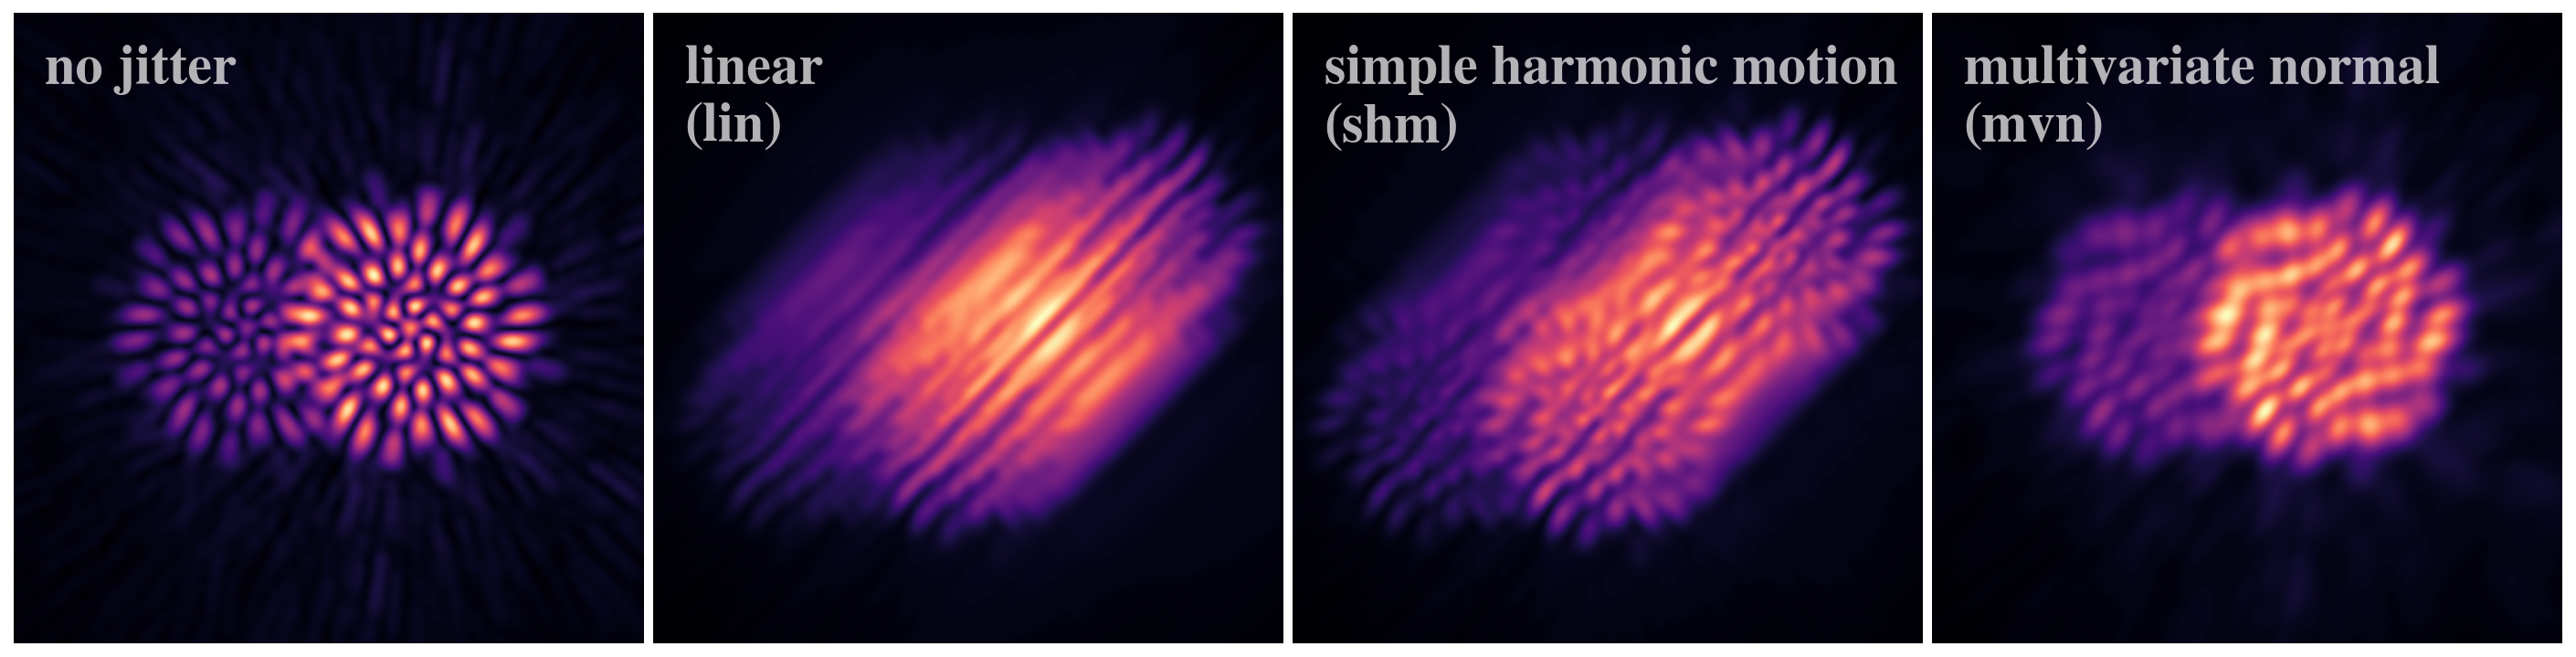

In [14]:
def text(ax, title):
    ax.text(
        0.05,
        0.95,
        title,
        color="white",
        size=14.5,
        transform=ax.transAxes,
        ha="left",
        va="top",
        alpha=0.7,
        fontweight="bold",
    )


fig, ax = plt.subplots(
    1, 4, figsize=(12, 3), sharey=True, gridspec_kw={"wspace": 0.015}
)
n = 50
ax[0].imshow(stable[n:-n, n:-n], cmap="magma", norm=mpl.colors.PowerNorm(0.6))
text(ax[0], "no jitter")

ax[1].imshow(lin[n:-n, n:-n], cmap="magma", norm=mpl.colors.PowerNorm(0.8))
text(ax[1], "linear \n(lin)")

ax[2].imshow(shm[n:-n, n:-n], cmap="magma", norm=mpl.colors.PowerNorm(0.8))
text(ax[2], "simple harmonic motion \n(shm)")

ax[3].imshow(mvn[n:-n, n:-n], cmap="magma", norm=mpl.colors.PowerNorm(0.7))
text(ax[3], "multivariate normal \n(mvn)")

for i in range(len(ax)):
    ax[i].axis("off")

plt.savefig(files_path + "figs/visuals.pdf", bbox_inches="tight", dpi=500)
plt.savefig(files_path + "figs/visuals.png", bbox_inches="tight", dpi=500)
plt.show()